<a href="https://colab.research.google.com/github/d3m1d0s/FoML_exercises/blob/main/fml_08_student_en_active_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fundamentals of Machine Learning — Exercise 8

## Dimensionality Reduction and Latent Spaces

Real datasets often contain many correlated or redundant features. Dimensionality reduction creates a smaller representation that may help us:

- visualise high-dimensional data,
- compress information,
- remove some redundancy or noise,
- prepare features for another model,
- inspect latent structure.

This exercise compares four important approaches:

- **Principal Component Analysis (PCA)**,
- **Truncated Singular Value Decomposition (SVD)**,
- **t-distributed Stochastic Neighbour Embedding (t-SNE)**,
- **Uniform Manifold Approximation and Projection (UMAP)**.

The classroom workflow remains:

> **question → prediction → computation → visualisation → interpretation → verification**

### Learning outcomes

After completing this exercise, you should be able to:

- explain what a principal component represents,
- distinguish explained variance from reconstruction quality,
- explain why scaling can change PCA,
- select a defensible number of principal components,
- reconstruct data from a lower-dimensional PCA representation,
- explain when TruncatedSVD is useful for sparse data,
- distinguish compression methods from visualisation methods,
- compare PCA, t-SNE, and UMAP cautiously,
- explain why distances and cluster sizes in t-SNE plots can be misleading,
- use local-neighbourhood evidence to audit an embedding,
- fit dimensionality reduction inside a leakage-safe modelling pipeline,
- use AI to question an interpretation after producing your own answer.

**Recommended duration:** 100–120 minutes.  
The final latent-space audit may be completed as homework.

## How to work in this exercise

Most code is already prepared. Your task is to:

1. **predict** before running a result,
2. **change** only clearly marked settings,
3. **connect** plots to a mathematical or geometric idea,
4. **compare** alternative representations,
5. **state** what cannot be concluded from a visualisation,
6. **verify** at least one visual claim numerically or in the original feature space.

A beautiful two-dimensional plot is not automatically a faithful map of the original data.

## 0. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits, load_wine
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE, trustworthiness
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 1. PCA begins with a direction of maximum variance

Consider a two-dimensional dataset whose features are strongly correlated.

Before running the cell, predict:

1. In which direction does the cloud vary most?
2. Would a horizontal or vertical one-dimensional projection preserve the data well?
3. What direction would you choose if only one coordinate could be retained?

**Answer:**
- the code builds Feature 2 as `1.8 * x1` plus a little noise, so the cloud should vary most along a diagonal line rising with slope about 1.8, steeper than 45 degrees
- neither would preserve it well: a horizontal projection keeps only Feature 1 and a vertical one only Feature 2, so each throws away one feature, while the cloud spreads along the diagonal where both features change together
- not Feature 1 or Feature 2, but a new coordinate measured along the direction in which the cloud varies most, a combination of both features. Projecting the points onto this direction keeps most of their spread and loses only the small spread across it, which comes from the noise

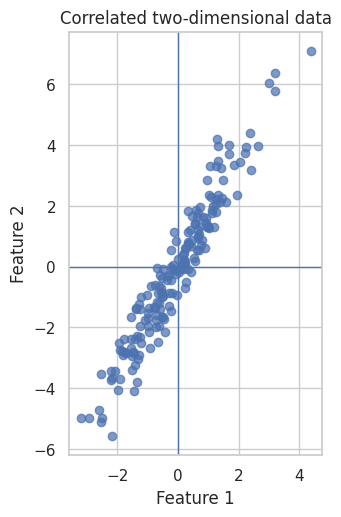

In [2]:
rng = np.random.default_rng(RANDOM_STATE)

x1 = rng.normal(0, 1.5, 180)
x2 = 1.8 * x1 + rng.normal(0, 0.65, 180)
# x2 = 1.8 * x1
X_geometry = np.column_stack([x1, x2])

plt.figure(figsize=(7, 5.5))
plt.scatter(X_geometry[:, 0], X_geometry[:, 1], alpha=0.72)
plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)
plt.gca().set_aspect('equal', adjustable='box')
plt.title('Correlated two-dimensional data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

### Compute the principal directions from the covariance matrix

For centred data, PCA finds eigenvectors of the covariance matrix.

- The first eigenvector points in the direction of maximum variance.
- The second eigenvector is orthogonal to the first.
- Eigenvalues quantify variance along those directions.

In [3]:
X_centered = X_geometry - X_geometry.mean(axis=0)
covariance_matrix = np.cov(X_centered, rowvar=False)

eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

manual_variance_ratio = eigenvalues / eigenvalues.sum()

print('Covariance matrix:')
display(pd.DataFrame(covariance_matrix, index=['Feature 1', 'Feature 2'], columns=['Feature 1', 'Feature 2']).round(3))

print('Explained variance ratio:')
display(pd.Series(manual_variance_ratio, index=['PC1', 'PC2']).round(3))

Covariance matrix:


,Feature 1,Feature 2
Feature 1,1.693,2.989
Feature 2,2.989,5.714


Explained variance ratio:


,0
PC1,0.986
PC2,0.014


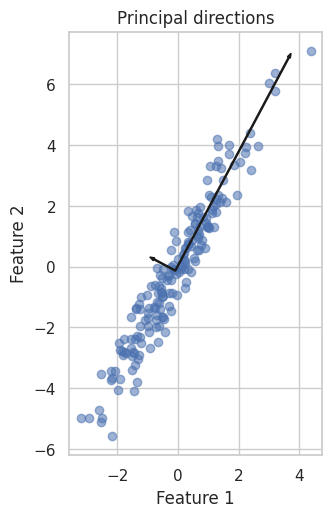

In [4]:
mean_point = X_geometry.mean(axis=0)
scale = 3.0

plt.figure(figsize=(7, 5.5))
plt.scatter(X_geometry[:, 0], X_geometry[:, 1], alpha=0.55)

for component_index in range(2):
    direction = eigenvectors[:, component_index]
    length = scale * np.sqrt(eigenvalues[component_index])
    plt.arrow(
        mean_point[0],
        mean_point[1],
        direction[0] * length,
        direction[1] * length,
        width=0.035,
        length_includes_head=True,
        label=f'PC{component_index + 1}',
        color = 'k',
    )

plt.gca().set_aspect('equal', adjustable='box')
plt.title('Principal directions')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

### Activity 1 — Interpret the geometry

Complete the explanation:

> PC1 points approximately along the cloud, up and to the right and steeper than 45 degrees, because this is the direction in which the points spread most: the two features rise together (covariance 2.989, a positive number), and Feature 2 varies more than Feature 1 (variance 5.714 against 1.693).
>
> PC1 preserves about 98.6% (0.986) of the total variance.
>
> Reducing the dataset to one component loses mainly the small spread across the cloud, along PC2 (1.4%), that is, how far each point lies off the diagonal because of the noise.

Why can the sign of a principal component be reversed without changing the solution?
- a principal component is a direction, a line through the centre of the cloud. An arrow pointing up and to the right and an arrow pointing down and to the left lie on the same line, so both describe the same component. Reversing the sign only reverses the sign of every point's position along that line, while the spread along it, and therefore the explained variance, stays exactly the same

### Project to one dimension and reconstruct

PCA compression has two steps:

1. project observations onto the selected component,
2. reconstruct an approximation in the original feature space.

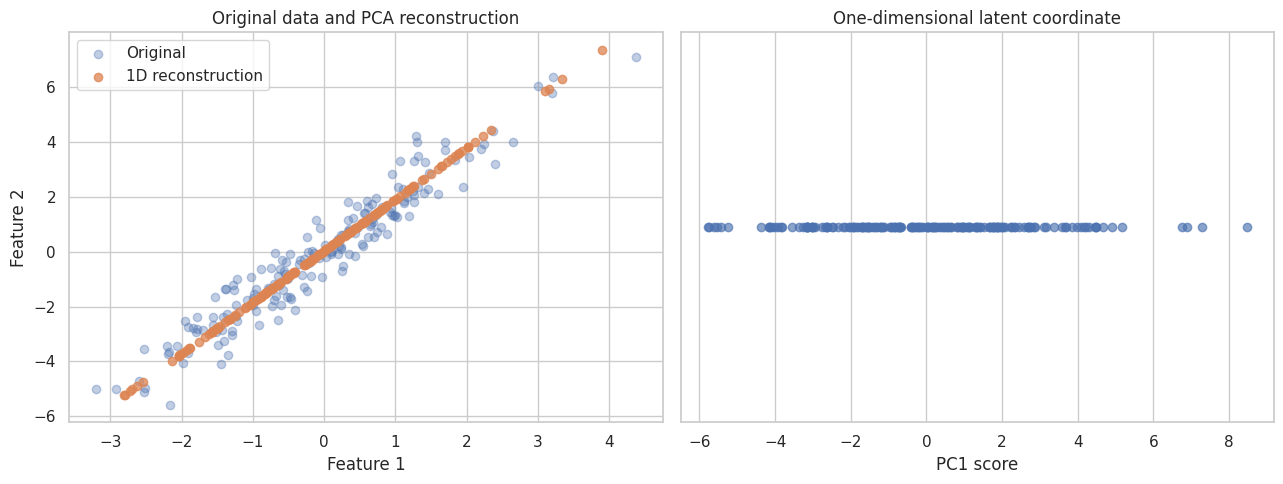

Reconstruction MSE: 0.0500


In [5]:
pca_one = PCA(n_components=1)
X_one_dimensional = pca_one.fit_transform(X_geometry)
X_reconstructed = pca_one.inverse_transform(X_one_dimensional)

reconstruction_mse = np.mean((X_geometry - X_reconstructed) ** 2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X_geometry[:, 0], X_geometry[:, 1], alpha=0.35, label='Original')
axes[0].scatter(X_reconstructed[:, 0], X_reconstructed[:, 1], alpha=0.75, label='1D reconstruction')
axes[0].set_title('Original data and PCA reconstruction')
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')
axes[0].legend()

axes[1].scatter(X_one_dimensional[:, 0], np.zeros(len(X_one_dimensional)), alpha=0.65)
axes[1].set_title('One-dimensional latent coordinate')
axes[1].set_xlabel('PC1 score')
axes[1].set_yticks([])

plt.tight_layout()
plt.show()

print(f'Reconstruction MSE: {reconstruction_mse:.4f}')

### Verification checkpoint

Compare the original and reconstructed points.

- Which direction of variation was removed?
- Does high explained variance mean perfect reconstruction?
- What would happen if the original cloud were approximately circular?

**Answer:**
- the variation across the cloud, along PC2, was removed. Every reconstructed point lies exactly on one straight line along the cloud, so the distance of each original point from that line, caused by the noise, is gone
- no. PC1 keeps 98.6% of the variance, but the reconstruction MSE is 0.0500, not 0: the points are moved onto the line, and the lost 1.4% is exactly their offset from it. This also fits the numbers: the lost variance along PC2 is about 0.014 · 7.407 ≈ 0.10, and the MSE averages it over the two features, 0.10 / 2 ≈ 0.05
- no direction would stand out. Both components would hold about half of the variance, so keeping one component would lose about half of the information, and the reconstruction would be poor

## 2. Scaling can change the meaning of PCA

The Wine dataset contains chemical measurements with very different units and numerical ranges.

Before running PCA, predict:

1. Which feature is likely to dominate PCA without scaling?
2. Does a large numerical variance automatically mean that a feature is scientifically more important?
3. What question does standardisation change?

**Answer:**
- proline. In Exercise 4 the same Wine data showed a standard deviation of about 315 for proline, more than 20 times that of magnesium (about 14), the feature with the next largest spread. PCA looks for the direction of largest variance, so without scaling PC1 should point almost entirely along proline
- no. The variance depends on the units in which a feature is measured: proline is simply recorded in much larger numbers. A feature with small numbers, such as hue, can separate the wines just as well
- without scaling, PCA asks in which direction the raw values vary most, and the answer is decided by the units. After standardisation every feature has mean 0 and standard deviation 1, so PCA asks which combination of features varies most together, with every feature counted equally

In [6]:
wine = load_wine(as_frame=True)
X_wine = wine.data.copy()
y_wine = wine.target.copy()

wine_scale_table = X_wine.agg(['mean', 'std', 'min', 'max']).T
wine_scale_table['range'] = wine_scale_table['max'] - wine_scale_table['min']
display(wine_scale_table.sort_values('std', ascending=False).round(2))

,mean,std,min,max,range
proline,746.89,314.91,278.00,1680.00,1402.00
magnesium,99.74,14.28,70.00,162.00,92.00
alcalinity_of_ash,19.49,3.34,10.60,30.00,19.40
color_intensity,5.06,2.32,1.28,13.00,11.72
malic_acid,2.34,1.12,0.74,5.80,5.06
flavanoids,2.03,1.00,0.34,5.08,4.74
alcohol,13.00,0.81,11.03,14.83,3.80
od280/od315_of_diluted_wines,2.61,0.71,1.27,4.00,2.73
total_phenols,2.30,0.63,0.98,3.88,2.90
proanthocyanins,1.59,0.57,0.41,3.58,3.17


In [7]:
pca_raw = PCA(n_components=2)
X_wine_raw_pca = pca_raw.fit_transform(X_wine)

wine_scaler = StandardScaler()
X_wine_scaled = wine_scaler.fit_transform(X_wine)

pca_scaled = PCA(n_components=2)
X_wine_scaled_pca = pca_scaled.fit_transform(X_wine_scaled)

raw_loadings = pd.Series(
    np.abs(pca_raw.components_[0]),
    index=X_wine.columns,
    name='absolute PC1 loading — raw',
).sort_values(ascending=False)

scaled_loadings = pd.Series(
    np.abs(pca_scaled.components_[0]),
    index=X_wine.columns,
    name='absolute PC1 loading — scaled',
).sort_values(ascending=False)

comparison_loadings = pd.concat([raw_loadings, scaled_loadings], axis=1)
display(comparison_loadings.head(8).round(3))

,absolute PC1 loading — raw,absolute PC1 loading — scaled
proline,1.000,0.287
magnesium,0.018,0.142
alcalinity_of_ash,0.005,0.239
color_intensity,0.002,0.089
alcohol,0.002,0.144
flavanoids,0.002,0.423
total_phenols,0.001,0.395
od280/od315_of_diluted_wines,0.001,0.376


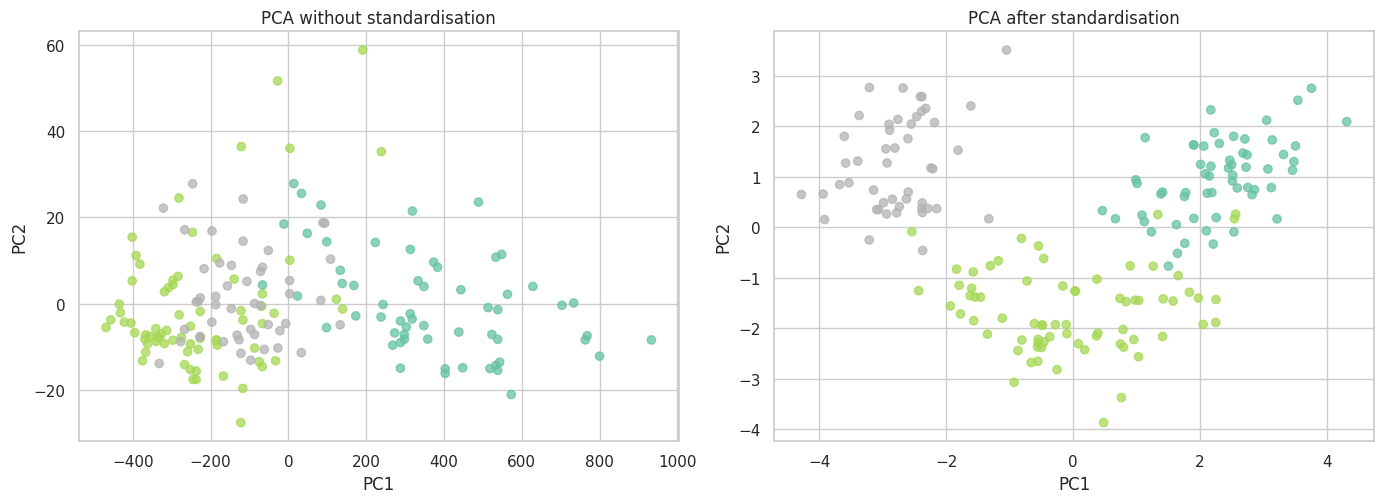

Explained variance, raw: [0.998 0.002]
Explained variance, scaled: [0.362 0.192]


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

axes[0].scatter(X_wine_raw_pca[:, 0], X_wine_raw_pca[:, 1], c=y_wine, cmap = 'Set2', alpha=0.75)
axes[0].set_title('PCA without standardisation')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

axes[1].scatter(X_wine_scaled_pca[:, 0], X_wine_scaled_pca[:, 1], c=y_wine, cmap = 'Set2', alpha=0.75)
axes[1].set_title('PCA after standardisation')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()

print('Explained variance, raw:', np.round(pca_raw.explained_variance_ratio_, 3))
print('Explained variance, scaled:', np.round(pca_scaled.explained_variance_ratio_, 3))

### Activity 2 — Explain what scaling changed

1. Which feature dominated raw PC1?
- proline: its absolute loading on raw PC1 is 1.000, while every other feature has 0.018 or less, and raw PC1 explains 0.998 of the variance

2. Why did this happen?
- because proline has by far the largest numbers: its standard deviation is 314.91, against 14.28 for magnesium, the next largest. PCA looks for the direction of largest variance, and without scaling that is simply the proline axis. The raw plot shows the result: PC1 runs from about -400 to 900, in proline units, and two of the three cultivars (the colours) overlap heavily, because proline alone does not separate them

3. What does standardised PCA consider equally before learning the components?
- every feature: after standardisation each has mean 0 and standard deviation 1, so no feature counts more because of its units. The components then follow features that vary together: among the 8 features in the loading table, scaled PC1 is led by flavanoids (0.423), total phenols (0.395) and od280/od315 (0.376), with proline only at 0.287. Scaled PC1 explains 0.362 and PC2 0.192 of the variance, and the scaled plot shows three fairly separate groups

4. Is standardisation always mandatory? State one situation in which original units may be meaningful.
- no. When all features are measured in the same unit and a larger spread really means more variation, for example the lengths of different body parts all in centimetres, scaling would hide differences that matter, and PCA on the original units can be the better choice

## 3. How many principal components should we keep?

We now use handwritten digit images.

Each 8×8 image becomes a vector of 64 pixel intensities. PCA can compress those 64 features into fewer latent coordinates.

Observations: 1797
Original features: 64
Image shape: (8, 8)


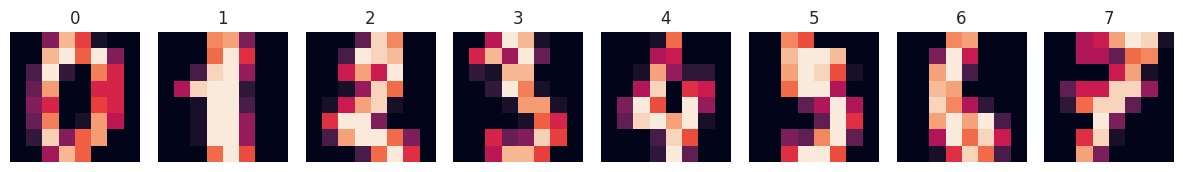

In [9]:
digits = load_digits()
X_digits = digits.data
y_digits = digits.target
images_digits = digits.images

print('Observations:', X_digits.shape[0])
print('Original features:', X_digits.shape[1])
print('Image shape:', images_digits.shape[1:])

fig, axes = plt.subplots(1, 8, figsize=(12, 2.2))
for axis, image, label in zip(axes, images_digits[:8], y_digits[:8]):
    axis.imshow(image)
    axis.set_title(str(label))
    axis.axis('off')
plt.tight_layout()
plt.show()

### Predict before viewing the curve

How many components do you expect to need for:

- approximately 80% of the variance?
- approximately 90%?
- approximately 95%?

Do you expect 95% explained variance to require 95% of the original 64 features? Why or why not?

**Answer:**
- my estimates: around 10 to 15 components for 80%, around 20 for 90% and around 30 for 95%. In the example images, the pixels at the left and right edges are dark in every digit, and the bright strokes cover several neighbouring pixels at once, so far fewer than 64 directions should be needed
- no. 95% of the variance is not the same as 95% of the features (about 61 of the 64). The variance is not spread evenly over the pixels: edge pixels that are almost always dark hardly vary at all, and neighbouring pixels along a stroke get brighter or darker together, so one component can describe many pixels at once

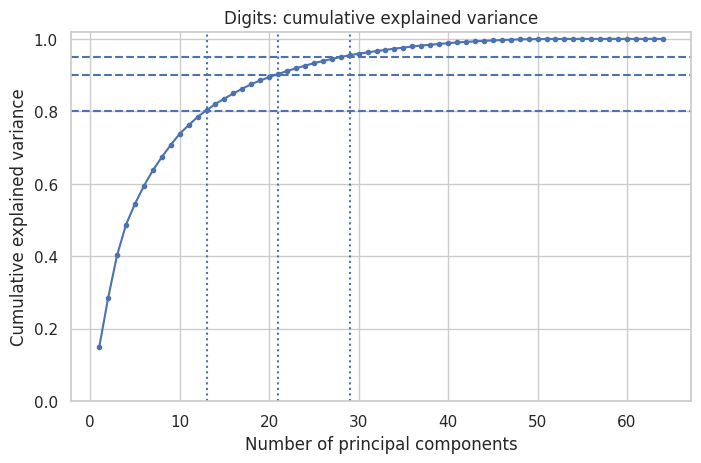

,minimum components
variance threshold,
0.80,13
0.90,21
0.95,29


In [10]:
pca_digits_full = PCA()
X_digits_pca_full = pca_digits_full.fit_transform(X_digits)

cumulative_variance = np.cumsum(pca_digits_full.explained_variance_ratio_)
thresholds = [0.80, 0.90, 0.95]
components_for_threshold = {
    threshold: int(np.argmax(cumulative_variance >= threshold) + 1)
    for threshold in thresholds
}

plt.figure(figsize=(8, 4.8))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', markersize=3)
for threshold in thresholds:
    plt.axhline(threshold, linestyle='--')
    plt.axvline(components_for_threshold[threshold], linestyle=':')
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative explained variance')
plt.title('Digits: cumulative explained variance')
plt.ylim(0, 1.02)
plt.show()

pd.Series(
    components_for_threshold,
    name='minimum components',
).rename_axis('variance threshold').to_frame()

### Activity 3 — Choose a dimensionality for a stated purpose

Complete the recommendations:

> For strong compression with visible information loss, I would test approximately 5 to 10 components, which keep only about 55% to 74% of the variance according to the curve.
>
> For retaining at least 90% of the variance, I need 21 components (13 are enough for 80% and 29 for 95%, close to my predictions of around 10 to 15, 20 and 30).
>
> I would not choose the number only from the curve because it has no sharp elbow: it rises steeply at first and then flattens gradually, so the 80%, 90% or 95% line is a choice, not something the curve decides. The curve also only says how much of the pixel variation is kept, not whether the digits stay recognisable or whether a model can still tell them apart, so the reconstructions and the purpose have to be checked as well.

Why is explained variance a property of the features, not a direct measure of classification accuracy?
- PCA is computed only from the pixel values (`X_digits`), the labels `y_digits` are not used at all. It finds the directions in which the images differ most from each other, without knowing whether these differences help to recognise the digit
- the two do not have to match. If some people write with thick strokes and others with thin ones, stroke thickness changes many pixels and is a direction with a lot of variance, but a thick 3 and a thin 3 are still both a 3. On the other hand, a 3 and an 8 differ only in a few pixels on the left, where the 8 is closed. This is a small difference compared with the whole image, so it can end up in a later, low-variance component, although it is exactly what separates these two digits
- so explained variance measures how much of the features' variation is kept, not how much information about the classes. That can only be checked by training and evaluating a model

### Reconstruct digits from different latent dimensions

Change `COMPONENT_COUNTS` only after viewing the first result.

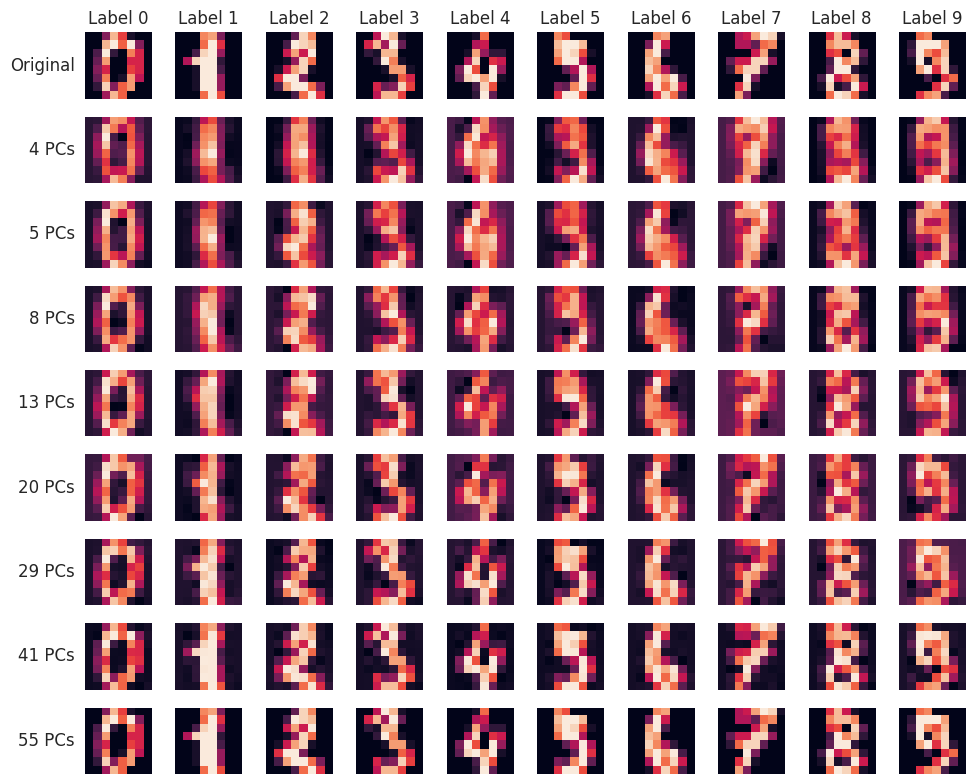

,components,explained variance,reconstruction MSE
0,4,0.487,9.628
1,5,0.545,8.542
2,8,0.674,6.122
3,13,0.803,3.700
4,20,0.894,1.984
5,29,0.955,0.849
6,41,0.990,0.186
7,55,1.000,0.000


In [11]:
COMPONENT_COUNTS = [4, 5, 8, 13, 20, 29, 41, 55]
SAMPLE_INDICES = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

fig, axes = plt.subplots(
    len(COMPONENT_COUNTS) + 1,
    len(SAMPLE_INDICES),
    figsize=(10, 8),
)

for column, sample_index in enumerate(SAMPLE_INDICES):
    axes[0, column].imshow(images_digits[sample_index])
    axes[0, column].set_title(f'Label {y_digits[sample_index]}')
    axes[0, column].axis('off')

axes[0, 0].text(-0.15, 0.5, 'Original', transform=axes[0, 0].transAxes, ha='right', va='center')

reconstruction_rows = []

for row, component_count in enumerate(COMPONENT_COUNTS, start=1):
    pca_model = PCA(n_components=component_count)
    transformed = pca_model.fit_transform(X_digits)
    reconstructed = pca_model.inverse_transform(transformed)

    mse = np.mean((X_digits - reconstructed) ** 2)
    reconstruction_rows.append({
        'components': component_count,
        'explained variance': pca_model.explained_variance_ratio_.sum(),
        'reconstruction MSE': mse,
    })

    for column, sample_index in enumerate(SAMPLE_INDICES):
        axes[row, column].imshow(reconstructed[sample_index].reshape(8, 8))
        axes[row, column].axis('off')

    axes[row, 0].text(-0.15, 0.5, f'{component_count} PCs', transform=axes[row, 0].transAxes, ha='right', va='center')

plt.tight_layout()
plt.show()

pd.DataFrame(reconstruction_rows).round(3)

### Activity 4 — Connect numbers to visible information

`COMPONENT_COUNTS` was extended to 4, 5, 8, 13, 20, 29, 41 and 55 components, and `SAMPLE_INDICES` to the first ten images, one of each digit, so that the transition can be seen in finer steps.

1. At what component count do the digit identities become reliably recognisable?
- at about 20 components (89.4% of the variance, MSE 1.984), all ten digits can be recognised. At 13 components most of them already can, but the 8 and the 9 are still unclear, and with 4 to 8 components the digits look like similar blurry blobs. From 41 components on, the reconstructions look almost identical to the originals

2. Which details disappear first?
- the fine details: the exact ends of the strokes, small gaps and closed loops (such as the closed loop of the 8) and thin lines. With few components the dark background also turns into a purple haze, and the digits become smooth, averaged shapes; the 1, for example, becomes a wide bar

3. Does the reconstruction MSE decrease monotonically? Why?
- yes: 9.628, 8.542, 6.122, 3.700, 1.984, 0.849, 0.186 and 0.000. Each model keeps the same first components as the smaller one and adds more of them in order of decreasing variance, so the reconstruction can only get closer to the original. The MSE falls together with the variance that is not kept, and at 55 components it reaches 0.000 with an explained variance of 1.000, because the remaining 9 of the 64 directions carry practically no variance, which fits the always-dark edge pixels

4. Could a classifier still work well on a reconstruction that looks imperfect to a human?
- possibly yes: a classifier does not need a sharp image, only the differences that separate the digits. At 13 components, for example, the images are blurry, but a 0 and a 1 still look clearly different. Whether that is enough for all ten digits can only be checked by training and evaluating a classifier on the reduced data, which this cell does not do

## 4. TruncatedSVD for sparse text data

PCA centres every feature, which can destroy sparsity. For a document–term matrix with many zeros, **TruncatedSVD** is often more practical because it operates without centring the matrix.

We will create a tiny bag-of-words dataset. The original words are high-dimensional observed features; the SVD components form a lower-dimensional latent representation.

In [12]:
documents = [
    'machine learning model data prediction',
    'classification model training data',
    'clustering features distance algorithm',
    'neural network model optimisation',
    'bread recipe flour yeast baking',
    'vegetable soup recipe cooking kitchen',
    'cake chocolate sugar baking recipe',
    'pasta sauce tomato cooking meal',
    'mountain hiking trail forest route',
    'travel train hotel city trip',
    'camping tent lake outdoor trip',
    'hiking map summit mountain route',
]

document_names = [
    'ML 1', 'ML 2', 'ML 3', 'ML 4',
    'Food 1', 'Food 2', 'Food 3', 'Food 4',
    'Travel 1', 'Travel 2', 'Travel 3', 'Travel 4',
]

vectorizer = CountVectorizer(stop_words='english')
X_text = vectorizer.fit_transform(documents)
terms = np.array(vectorizer.get_feature_names_out())

print('Document–term matrix shape:', X_text.shape)
print('Non-zero proportion:', round(X_text.nnz / (X_text.shape[0] * X_text.shape[1]), 3))

Document–term matrix shape: (12, 46)
Non-zero proportion: 0.103


### Predict the latent structure

How many broad themes do you expect?

Which words should receive strong weights in a component related to:

- machine learning,
- food,
- travel or hiking?

**Answer:**
- three broad themes, one for each group of four documents: machine learning, food and travel. The groups share no words, and each document contains only a few of the 46 terms (10.3% of the matrix is non-zero), so the themes should separate well
- the strongest weights should go to the words that appear in several documents of the same group, because they connect these documents:
  - machine learning: `model` (in three documents) and `data` (in two)
  - food: `recipe` (in three), `baking` and `cooking` (in two each)
  - travel or hiking: `hiking`, `mountain`, `route` and `trip` (in two each)

  Words that appear in only one document, such as `bread` or `tent`, should get smaller weights

In [13]:
svd_text = TruncatedSVD(n_components=3, random_state=RANDOM_STATE)
X_text_latent = svd_text.fit_transform(X_text)

component_rows = []
for component_index, component in enumerate(svd_text.components_, start=1):
    top_indices = np.argsort(np.abs(component))[::-1][:7]
    component_rows.append({
        'component': f'Component {component_index}',
        'top weighted terms': ', '.join(terms[top_indices]),
        'explained variance ratio': svd_text.explained_variance_ratio_[component_index - 1],
    })

latent_documents = pd.DataFrame(
    X_text_latent,
    index=document_names,
    columns=['Latent 1', 'Latent 2', 'Latent 3'],
)

display(pd.DataFrame(component_rows).round(3))
display(latent_documents.round(3))

,component,top weighted terms,explained variance ratio
0,Component 1,"route, mountain, hiking, forest, trail, summit...",0.133
1,Component 2,"recipe, baking, cooking, chocolate, sugar, cak...",0.110
2,Component 3,"model, data, prediction, machine, learning, tr...",0.109


,Latent 1,Latent 2,Latent 3
ML 1,-0.0,0.000,1.908
ML 2,0.0,-0.000,1.539
ML 3,0.0,0.000,-0.000
ML 4,-0.0,0.000,1.083
Food 1,0.0,1.687,-0.000
Food 2,0.0,1.373,0.000
Food 3,0.0,1.687,-0.000
Food 4,0.0,0.488,0.000
Travel 1,2.0,-0.000,0.000
Travel 2,0.0,0.000,-0.000


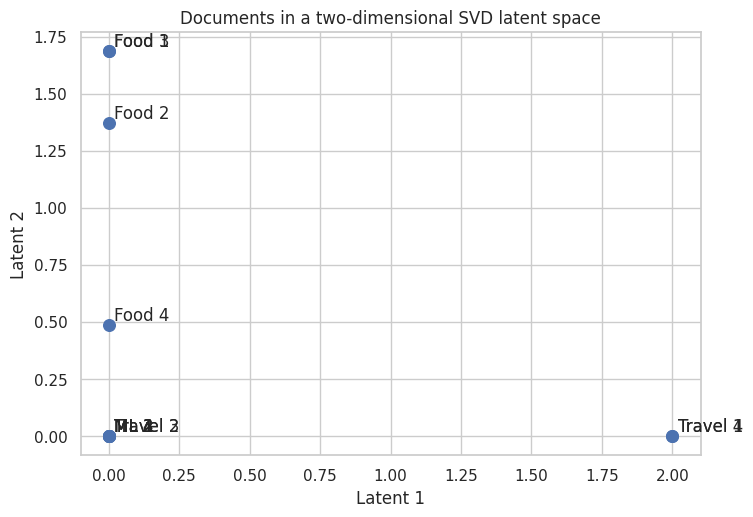

In [14]:
plt.figure(figsize=(8, 5.5))
plt.scatter(latent_documents['Latent 1'], latent_documents['Latent 2'], s=70)

for name, row in latent_documents.iterrows():
    plt.text(row['Latent 1'] + 0.02, row['Latent 2'] + 0.02, name)

plt.title('Documents in a two-dimensional SVD latent space')
plt.xlabel('Latent 1')
plt.ylabel('Latent 2')
plt.show()

### Activity 5 — Interpret a latent component cautiously

Choose one component and complete:

> This component appears related to __________ because the strongly weighted terms include __________.
>
> It should not be called a hard topic label because __________.

Why may the sign of an SVD component change between implementations or runs without changing its underlying axis?

## 5. PCA versus t-SNE for two-dimensional visualisation

PCA is linear and preserves directions of large global variance. t-SNE is non-linear and focuses on preserving local neighbourhood probabilities.

Important caution:

> t-SNE is excellent for exploring local neighbourhoods, but distances between distant islands, island orientation, and apparent island size are not directly trustworthy.

We use a stratified subset of the digits data to keep the experiment fast.

In [ ]:
_, X_digits_view, _, y_digits_view = train_test_split(
    X_digits,
    y_digits,
    test_size=900,
    stratify=y_digits,
    random_state=RANDOM_STATE,
)

X_digits_view_scaled = StandardScaler().fit_transform(X_digits_view)

pca_view = PCA(n_components=2, random_state=RANDOM_STATE)
embedding_pca = pca_view.fit_transform(X_digits_view_scaled)

PERPLEXITIES = [5, 30, 80]
embeddings_tsne = {}

for perplexity in PERPLEXITIES:
    model = TSNE(
        n_components=2,
        perplexity=perplexity,
        learning_rate='auto',
        init='pca',
        max_iter=700,
        random_state=RANDOM_STATE,
    )
    embeddings_tsne[perplexity] = model.fit_transform(X_digits_view_scaled)

### Predict before plotting

As perplexity increases, do you expect the embedding to emphasise very local or broader neighbourhoods?

Which visual properties do you expect to remain stable across several perplexities?

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.8))

axes[0].scatter(embedding_pca[:, 0], embedding_pca[:, 1], c=y_digits_view, s=18, alpha=0.72)
axes[0].set_title('PCA — 2 components')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

for axis, perplexity in zip(axes[1:], PERPLEXITIES):
    embedding = embeddings_tsne[perplexity]
    axis.scatter(embedding[:, 0], embedding[:, 1], c=y_digits_view, s=18, alpha=0.72)
    axis.set_title(f't-SNE — perplexity {perplexity}')
    axis.set_xlabel('Dimension 1')
    axis.set_ylabel('Dimension 2')

plt.tight_layout()
plt.show()

### Activity 6 — Separate observation from overclaim

Write one supported observation and one claim that would be too strong.

**Supported observation:**  

**Too-strong claim:**  

Then answer:

1. Which digit classes form stable local groups across settings?
2. Which relationships change substantially?
3. Why can two distant islands in t-SNE not automatically be interpreted as very dissimilar classes?

### Audit local-neighbourhood preservation

`trustworthiness` asks whether points that appear close in the embedding were also reasonably close in the original feature space.

It is not a complete measure of embedding quality, but it provides evidence beyond visual appearance.

In [ ]:
trust_rows = [{
    'representation': 'PCA — 2 components',
    'trustworthiness': trustworthiness(
        X_digits_view_scaled,
        embedding_pca,
        n_neighbors=10,
    ),
}]

for perplexity, embedding in embeddings_tsne.items():
    trust_rows.append({
        'representation': f't-SNE — perplexity {perplexity}',
        'trustworthiness': trustworthiness(
            X_digits_view_scaled,
            embedding,
            n_neighbors=10,
        ),
    })

trust_table = pd.DataFrame(trust_rows).sort_values('trustworthiness', ascending=False)
trust_table.round(3)

### Verification checkpoint

1. Does the numerical audit agree with your visual impression?
2. Can a high trustworthiness score prove that all global distances are correct?
3. Why should several parameter settings be inspected rather than reporting one attractive t-SNE plot?

## 6. Optional UMAP comparison

UMAP is another non-linear embedding method. Two influential parameters are:

- `n_neighbors`: the local-versus-broader neighbourhood scale,
- `min_dist`: how tightly points may be packed in the embedding.

The next cell runs only when `umap-learn` is installed.

In Google Colab, install it once with:

```python
%pip install -q umap-learn
```

Then restart or rerun the import cell if necessary.

In [ ]:
try:
    import umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False
    print('UMAP is not installed. Run: %pip install -q umap-learn')

In [ ]:
UMAP_N_NEIGHBORS = 15
UMAP_MIN_DIST = 0.10

if UMAP_AVAILABLE:
    umap_model = umap.UMAP(
        n_components=2,
        n_neighbors=UMAP_N_NEIGHBORS,
        min_dist=UMAP_MIN_DIST,
        random_state=RANDOM_STATE,
    )
    embedding_umap = umap_model.fit_transform(X_digits_view_scaled)

    plt.figure(figsize=(7.5, 5.5))
    plt.scatter(embedding_umap[:, 0], embedding_umap[:, 1], c=y_digits_view, s=18, alpha=0.72)
    plt.title(
        f'UMAP — n_neighbors={UMAP_N_NEIGHBORS}, '
        f'min_dist={UMAP_MIN_DIST}'
    )
    plt.xlabel('Dimension 1')
    plt.ylabel('Dimension 2')
    plt.show()

    print(
        'Trustworthiness:',
        round(
            trustworthiness(
                X_digits_view_scaled,
                embedding_umap,
                n_neighbors=10,
            ),
            3,
        ),
    )
else:
    print('UMAP section skipped. PCA and t-SNE results remain available.')

### Optional interpretation

If UMAP ran, compare it with t-SNE:

- Which local groups appear stable in both methods?
- Which global relationships differ?
- What changes when `n_neighbors` is increased?
- Why should agreement between two methods increase confidence but still not prove a cluster structure?

## 7. Dimensionality reduction inside a modelling pipeline

When PCA is used before a supervised model, it must be fitted **inside** the training procedure.

Incorrect workflow:

1. fit PCA on the complete dataset,
2. cross-validate a classifier on the already transformed data.

Leakage-safe workflow:

1. each cross-validation fold fits scaling and PCA only on its training part,
2. the fitted transformation is applied to that fold's validation part.

A scikit-learn `Pipeline` enforces this sequence.

In [ ]:
X_wine_model = wine.data

y_wine_model = wine.target

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

baseline_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=3000)),
])

pca_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('pca', PCA(n_components=0.90)),
    ('classifier', LogisticRegression(max_iter=3000)),
])

baseline_scores = cross_validate(
    baseline_pipeline,
    X_wine_model,
    y_wine_model,
    cv=cv,
    scoring='accuracy',
    return_train_score=True,
)

pca_scores = cross_validate(
    pca_pipeline,
    X_wine_model,
    y_wine_model,
    cv=cv,
    scoring='accuracy',
    return_train_score=True,
)

pipeline_comparison = pd.DataFrame([
    {
        'pipeline': 'Scaled logistic regression',
        'mean train accuracy': baseline_scores['train_score'].mean(),
        'mean validation accuracy': baseline_scores['test_score'].mean(),
        'validation standard deviation': baseline_scores['test_score'].std(),
    },
    {
        'pipeline': 'Scaling + PCA(90%) + logistic regression',
        'mean train accuracy': pca_scores['train_score'].mean(),
        'mean validation accuracy': pca_scores['test_score'].mean(),
        'validation standard deviation': pca_scores['test_score'].std(),
    },
])

pipeline_comparison.round(3)

### Activity 7 — Interpret the modelling trade-off

1. Did PCA improve, preserve, or reduce validation accuracy?
2. Why might a lower-dimensional model still be useful even without higher accuracy?
3. Why is t-SNE not used in this pipeline?
4. What information would you need before claiming that PCA made the model “better”?

## Guided AI study activity — challenge a latent-space interpretation

First write your own interpretation of one t-SNE or UMAP plot.

**My initial interpretation:**  

Then use this prompt:

```text
Act as a cautious dimensionality-reduction tutor.
Do not rewrite my interpretation and do not tell me what the plot means.
Ask me exactly three short questions, one at a time:

1. Which relationships in this embedding are local, and which may be visually misleading?
2. What parameter, random seed, or alternative method should I compare?
3. What evidence from the original feature space or a numerical audit supports my claim?

Wait for my answer after each question.
```

Close the chat and record only:

**One useful question from AI:**  

**One sentence I revised:**  

**What evidence now supports the revised sentence:**  

Do not paste the complete conversation.

## 8. Assessed task — Latent-space audit (2 points)

Prepare a concise audit of dimensionality reduction on the digits data.

Use the prepared code and change at least **two** settings:

- one PCA component count,
- one t-SNE perplexity or random seed,
- optionally one UMAP `n_neighbors` or `min_dist` value.

Submit:

1. **Purpose:** compression, visualisation, or downstream modelling.
2. **PCA choice:** selected number of components and evidence from explained variance or reconstruction.
3. **Embedding comparison:** PCA plus t-SNE, and optionally UMAP.
4. **Stable observation:** one pattern visible under more than one defensible setting or method.
5. **Numerical audit:** trustworthiness or reconstruction MSE.
6. **Limitation:** one conclusion that the 2D plot cannot support.
7. **Recommendation:** which representation you would use for the stated purpose.
8. **AI note:** if AI was used, state one question it asked and one claim you independently verified.

### Marking

| Criterion | Points |
|---|---:|
| PCA dimensionality is justified with evidence | 0.50 |
| Embedding comparison uses more than one setting or method | 0.50 |
| Interpretation is cautious and supported | 0.50 |
| Numerical audit, limitation, and recommendation are coherent | 0.50 |

In [ ]:
# Change at least TWO clearly marked settings.

AUDIT_PCA_COMPONENTS = 20
AUDIT_TSNE_PERPLEXITY = 40
AUDIT_TSNE_SEED = 7

pca_audit_model = PCA(n_components=AUDIT_PCA_COMPONENTS)
X_audit_latent = pca_audit_model.fit_transform(X_digits)
X_audit_reconstructed = pca_audit_model.inverse_transform(X_audit_latent)

audit_reconstruction_mse = np.mean(
    (X_digits - X_audit_reconstructed) ** 2
)

tsne_audit_model = TSNE(
    n_components=2,
    perplexity=AUDIT_TSNE_PERPLEXITY,
    learning_rate='auto',
    init='pca',
    max_iter=700,
    random_state=AUDIT_TSNE_SEED,
)
embedding_tsne_audit = tsne_audit_model.fit_transform(X_digits_view_scaled)

audit_trustworthiness = trustworthiness(
    X_digits_view_scaled,
    embedding_tsne_audit,
    n_neighbors=10,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
)
axes[0].axvline(AUDIT_PCA_COMPONENTS, linestyle='--')
axes[0].set_title('Selected PCA dimensionality')
axes[0].set_xlabel('Number of components')
axes[0].set_ylabel('Cumulative explained variance')

axes[1].scatter(
    embedding_tsne_audit[:, 0],
    embedding_tsne_audit[:, 1],
    c=y_digits_view,
    s=18,
    alpha=0.72,
)
axes[1].set_title(
    f't-SNE: perplexity={AUDIT_TSNE_PERPLEXITY}, '
    f'seed={AUDIT_TSNE_SEED}'
)
axes[1].set_xlabel('Dimension 1')
axes[1].set_ylabel('Dimension 2')

plt.tight_layout()
plt.show()

pd.Series({
    'PCA components': AUDIT_PCA_COMPONENTS,
    'PCA explained variance': pca_audit_model.explained_variance_ratio_.sum(),
    'PCA reconstruction MSE': audit_reconstruction_mse,
    't-SNE trustworthiness': audit_trustworthiness,
}).round(3)

### Your latent-space audit

**Purpose:**  

**PCA choice and evidence:**  

**Methods/settings compared:**  

**Stable observation:**  

**Numerical audit:**  

**Unsupported conclusion I avoided:**  

**Recommendation:**  

**Optional verified AI note:**

# End-of-lab self-check

Before finishing, check that you can:

- [ ] explain PC1 as a direction of maximum variance,
- [ ] explain why component signs may flip,
- [ ] distinguish projection from reconstruction,
- [ ] explain how scaling changes PCA,
- [ ] use cumulative explained variance without treating it as the only criterion,
- [ ] relate component count to visible reconstruction quality,
- [ ] explain why TruncatedSVD is useful for sparse matrices,
- [ ] distinguish PCA from t-SNE and UMAP,
- [ ] state which visual properties of t-SNE are unreliable,
- [ ] audit an embedding with another setting, method, or numerical measure,
- [ ] place PCA inside a leakage-safe pipeline,
- [ ] revise an embedding claim after evidence-based questions.

Exercise 9 will focus on systematic hyperparameter optimisation with Optuna.